# Fusionar unidades sin perder el significado
## Pregunta y continuidad
¿Cómo conectar resúmenes producidos por la autoescala31 sin imponer una escala global previa? Se implementa reescalado+Chan conocido y se auditan órdenes, subnormales y costes. No se afirma innovación disciplinar.
# Fusionar resúmenes en unidades diferentes
## Pregunta, notación y original
Continuamos29Welford/Chan,30escalaexterna,31autoescala. Un resumen de observaciones finitas disjuntas A tiene n_A, exponente e_A, origen a_A, media relativa b_A y suma centrada Q_A, en unidades normalizadas y=x/2^{e_A}. Media μ_A=a_A+b_A. En unidades físicas U, media2^{e_A}μ_A, varianza U², SD U; n y exponentes adimensionales. Asumimos n≪2^53. El contrato no detecta solapamiento: el consumidor garantiza particiones disjuntas.

La expresión original Chan conocida (doi10.1080/00031305.1983.10483115) sobre la misma unidad es
$$\delta=\mu_B-\mu_A,\quad \mu=\mu_A+\delta n_B/(n_A+n_B),$$
$$Q=Q_A+Q_B+\delta^2 n_A n_B/(n_A+n_B).$$
Para derivar, separe Σ_A(y−μ)²=Σ_A[(y−μ_A)+(μ_A−μ)]². El término cruzado es0 porque Σ_A(y−μ_A)=0. Por tanto es Q_A+n_A(μ_A−μ)². Análogo B. Sustituya μ_A−μ=−δn_B/n y μ_B−μ=δn_A/n; suma de cuadrados extra δ²[n_A n_B²+n_B n_A²]/n²=δ²n_A n_B/n. No existe nuevo estimador.

## Brecha y adaptación al estado31
No se pueden fusionar Q_A y Q_B en escalas diferentes directamente. Elegimos E=max(e_A,e_B) entre resúmenes con algún dato no nulo: los ceros no determinan unidad. Si ambos son todo ceros E=0. Sea c_j=2^{e_j−E}. Cada y'_j=c_jy_j, luego a'_j=c_ja_j, b'_j=c_jb_j, Q'_j=c_j²Q_j (derivación31 conservada). Ahora ambas medias están expresadas en la misma unidad y se aplica Chan anterior.
$$a'_j=2^{e_j-E}a_j,\quad b'_j=2^{e_j-E}b_j,\quad Q'_j=2^{2(e_j-E)}Q_j.$$
$$\delta=(a'_B-a'_A)+(b'_B-b'_A),\quad n=n_A+n_B,$$
$$a=a'_A,\ b=b'_A+\delta n_B/n,\ Q=Q'_A+Q'_B+\delta^2 n_A n_B/n.$$
Esto corresponde exactamente al helper rebase y `Moments.merge`. Se calcula SD=2^E sqrt(Q/(n−d)), V=2^{2E}Q/(n−d), d∈{0,1}, n>d. Resumen vacío es identidad; n siempre suma. En aritmética real se conservan media, suma centrada, positividad y asociatividad/commutatividad del resultado estadístico. En máquina NO se conserva igualdad bit a bit por orden de reducción; tampoco se garantiza cota universal de error. Constantes/cero producen SD0. NaN/inf se rechazan al push, d/n inválidos al result.

## Condiciones, negativos y propiedades perdidas
Para resúmenes creados mediante API (no estados construidos arbitrariamente), normalización limita magnitudes. Reescalado puede redondear componentes a0; rounded_to_zero suma diagnósticos anteriores y nuevos, pero no mide toda información perdida ni cota de error. Reutilizar el mismo resumen en ambos lados duplica datos: no independencia ni deduplicación automáticas. La fusión es operación numérica sobre particiones, no inferencia de independencia estadística.

Ejemplo adverso: [1e−300,2e−300] fusionado con [1e300,2e300] descarta cantidades pequeñas al reescalar. SD puede seguir representable, pero sus contribuciones no se recuperan. Entradas redondeadas antes de ingresar siguen irrecuperables. Subnormal [-min,min] produce SD=min; [0,min] posee SD realmin/2 y puede abstenerse std_underflow. Resultado depende del árbol de cómputo; no teorema flotante. Ninguna mejora científica original ni implementación paralela; sólo componente conectable con pruebas.


In [1]:
import json,math,csv
from pathlib import Path
from IPython.display import display,Image
from src.dynamic import DynamicMoments
from src.benchmark_merge import summary,oracle,reduce_states
print(json.loads(Path('config_merge.json').read_text()))

{'seeds': [1101, 1102], 'sizes': [128, 1024], 'exponents': [-1070, 0, 1020], 'chunks': [2, 8], 'ddof': [0, 1], 'repeats': 5, 'dataset': 'synthetic normal, clipped to [-2,2] before ldexp; Decimal100 on received floats', 'gate': 'SD error <= max(4 ulp,1e-12 relative); no bitwise associativity claim'}


## Construcción de la herramienta paso a paso
Los chunks pueden venir de motores distintos en el futuro; hoy todoPython, ejecución secuencial. Observe e_A y e_B, la unidad común E y el conteo combinado. Ni almacenar datos originales ni reescanearlos es necesario al fusionar resúmenes.

In [2]:
left=summary([1.,2.,3.]);right=summary([1e200,2e200,3e200])
merged=left.merge(right)
print('Exponentes',left.exponent,right.exponent,'común',merged.exponent)
print('n=',merged.state.n,'SD/1e200=',merged.result().std/1e200)
expected=oracle([1.,2.,3.,1e200,2e200,3e200],0)
assert merged.state.n==6 and math.isclose(merged.result().std,expected,rel_tol=1e-12)
assert DynamicMoments().merge(left)==left

Exponentes 2 666 común 666
n= 6 SD/1e200= 1.1547005383792515


## Cero y subnormal son contratos distintos
Un chunk de ceros no debe fijar una escala0 y borrar la SD de datos diminutos. Fixtures hex preservan exactamente datosbinary64 recibidos para futuros contratos multilenguaje, aún no implementados.

In [3]:
tiny=math.ulp(0.)
z=summary([0.,0.]);s=summary([-tiny,tiny])
print('Cero+subnormal',z.merge(s).result())
print(json.loads(Path('fixtures_merge.json').read_text()))
assert s.result().std==tiny
assert z.merge(s).exponent==s.exponent
assert summary([0.]).merge(summary([tiny])).result().status=='std_underflow'

Cero+subnormal ScaleResult(n=4, exponent=-1073, status='variance_underflow', variance=0.0, std=5e-324)
{'format': 'binary64 hexadecimal; future cross-language fixtures, no extra language implementation claimed', 'cases': [{'name': 'simple', 'left': ['0x1.0000000000000p+0', '0x1.0000000000000p+1'], 'right': ['0x1.8000000000000p+1', '0x1.0000000000000p+2']}, {'name': 'subnormal', 'left': ['-0x0.0000000000001p-1022'], 'right': ['0x0.0000000000001p-1022']}, {'name': 'mixed', 'left': ['0x1.56e1fc2f8f359p-997', '0x1.56e1fc2f8f359p-996'], 'right': ['0x1.7e43c8800759cp+996', '0x1.7e43c8800759cp+997']}]}


## Benchmark, sensibilidad y justicia del contraste
48escenarios:2seeds×2n×3exponentes×2chunks×2ddof.5métodos,240filas. Umbral previo max(4ulp,1e−12relativo), Decimal100. Merge_left/tree miden sólo fusión precomputada; merge_tree_full incluye construirchunks y es comparable al recorrido serial. NumPy escalado incluye normalización y permanece baseline competitivo, con disponibilidadoffline no restricción streaming. No ejecución paralela ni speedup declarado.

In [4]:
results=json.loads(Path('results/merge_summary.json').read_text())
print(json.dumps(results,indent=2))
rows=list(csv.DictReader(Path('results/merge_raw.csv').open()))
print('Primeras5filas',rows[:5])
assert results['gate'] and results['scenario_count']==48
print('Costecompleto ns',results['median_ns']['merge_tree_full'],'serial',results['median_ns']['serial_dynamic'],'NumPy',results['median_ns']['numpy_scaled'])

{
  "scenario_count": 48,
  "rows": 240,
  "merged_comparisons": 144,
  "gate": true,
  "max_relative_error": 3.631143807943662e-16,
  "python": "3.12.14",
  "numpy": "2.3.5",
  "platform": "Linux-6.18.57-x86_64-with-glibc2.39",
  "hardware": "x86_64",
  "timing_scope": "merge_left/tree exclude precomputed chunk summary; merge_tree_full/serial/NumPy include input scan; no parallel speedup claim; 5 repeats; imports/install excluded; tracemalloc separate Python heap not RSS",
  "median_ns": {
    "serial_dynamic": 1026547.0,
    "merge_left": 23080.0,
    "merge_tree": 21728.0,
    "merge_tree_full": 1150098.0,
    "numpy_scaled": 95398.5
  }
}
Primeras5filas [{'seed': '1101', 'n': '128', 'exponent': '-1070', 'chunks': '2', 'ddof': '0', 'method': 'serial_dynamic', 'sd': '7.4e-323', 'oracle_sd': '7.4e-323', 'relative_error': '0.0', 'absolute_error': '0.0', 'gate': 'True', 'median_ns': '200672.0', 'peak_python_bytes': '728'}, {'seed': '1101', 'n': '128', 'exponent': '-1070', 'chunks': '2',

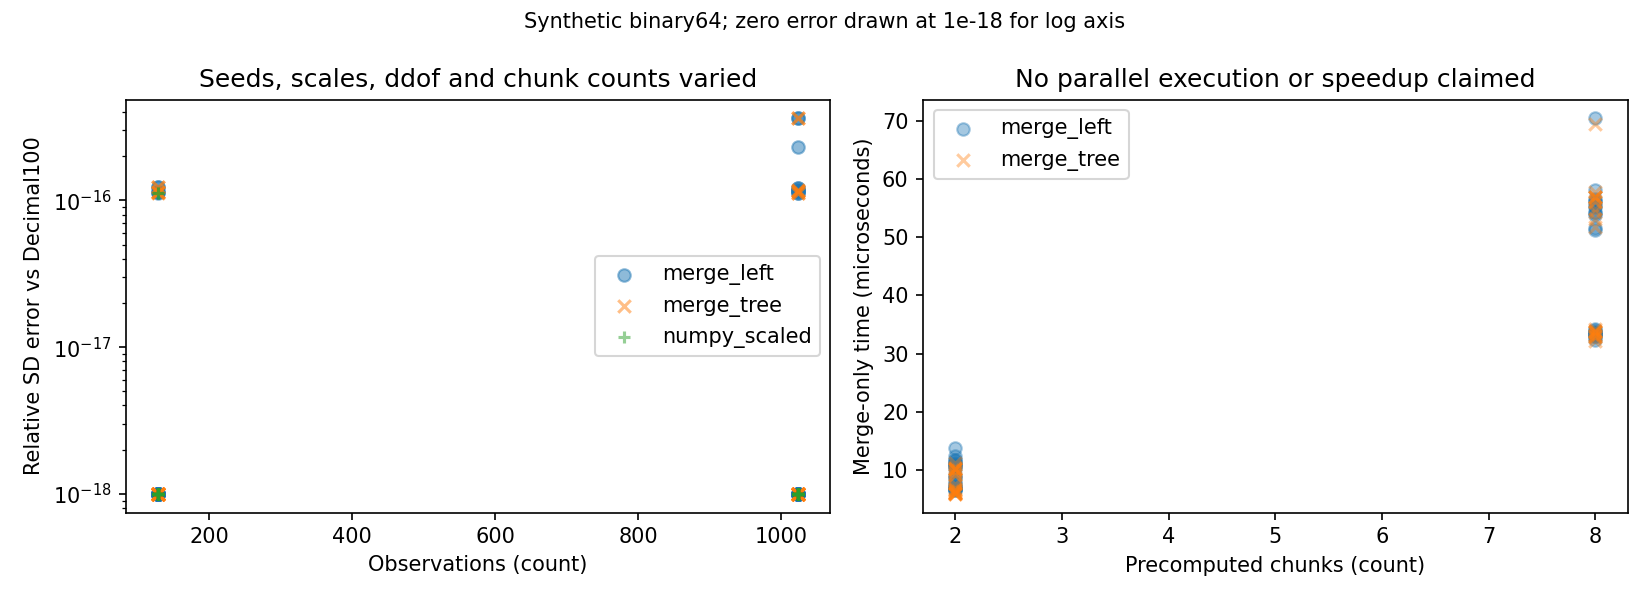

In [5]:
display(Image(filename='results/merge_audit.png'))

## Negativos: no asociatividad bit a bit y pérdida
Se explora diferencia entre árboles sobre los mismos datos sin escoger el árbol tras ver resultados. Ninguna identidad real garantiza bitsiguales. No duplicar un resumen para simular una partición disjunta; es responsabilidad del consumidor.

In [6]:
index={(r['seed'],r['n'],r['exponent'],r['chunks'],r['ddof'],r['method']):r for r in rows}
different=0
for key,row in index.items():
    if key[-1]=='merge_left':
        other=index[key[:-1]+('merge_tree',)]
        different+=float(row['sd'])!=float(other['sd'])
print('Diferencias binariasleft/tree:',different)
a=summary([1e-300,2e-300]);b=summary([1e300,2e300]);c=a.merge(b)
print('Componentesredondeadosa0diagnóstico:',c.rounded_to_zero)
assert c.rounded_to_zero>0
print('Duplicarresumen aumenta n:',a.merge(a).state.n,'no es deduplicación')

Diferencias binariasleft/tree: 5
Componentesredondeadosa0diagnóstico: 3
Duplicarresumen aumenta n: 4 no es deduplicación


## Decisión y siguiente hito
Continuar: permite combinación incremental de resúmenes sin elegir unidadexterna. Adaptación de ingeniería, prototipo verificado en escenarios sintéticos, no operacional. Ajustar ante redondeo, cerrar superioridad universal. Siguientegate: equivalencia multilenguaje usando fixtureshex y prueba de límites antes de exportar API. Matrizfuentes prior_art_merge.md; informe_merge.md14p y rúbricas. Se conserva todo29–31 sin reemplazar fórmulas/notebooks.